# League of Legends: Final Test Evaluation and Error Analysis

Owner: Yejune. Run notebooks 01–04 first. This notebook completes final evaluation of **Logistic Regression, Decision Tree, Random Forest, and HistGradientBoosting** at minutes **10, 14, 18, and 20**. Minute 14 is the primary comparison.

1. Reconstruct the selected configurations from **training-CV results only**.
2. Save the frozen model specifications before any held-out scoring.
3. Fit on all eligible training matches, predict the reserved test matches, and save predictions.
4. Generate comparison tables, ROC curves, confusion matrices, calibration curves, and descriptive error analyses from those predictions.

There is no tuning, threshold selection, or fitted probability calibration in this notebook. Classification uses probability 0.5 throughout. The preferred model is named from minute-14 CV before test results are inspected. Re-running unchanged cells reuses completed prediction files; if the frozen inputs/configurations change, execution stops instead of silently replacing the final evaluation.

## 1. Setup

Use the same project environment as notebooks 03 and 04. The first full run performs 16 final fits (four models × four minutes). It does not repeat the earlier CV searches.

In [1]:
import ast
import hashlib
import json
import platform
import sys
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, log_loss, roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "features.py").is_file()
     and (p / "data" / "raw" / "lol_ranked_games.csv").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.evaluation import SEED
from src.features import NOTEBOOK01_FEATURES, OBJECTIVE_FEATURES, TRAJECTORY_FEATURES, build_features

raw_path = root / "data" / "raw" / "lol_ranked_games.csv"
split_path = root / "data" / "processed" / "split_ids.csv"
source_report_dir = root / "reports"
report_dir = root / "reports"
figure_dir = report_dir / "figures"
prediction_dir = report_dir / "final_predictions"
MINUTES = [10, 14, 18, 20]
PRIMARY_MINUTE = 14
THRESHOLD = 0.5
CONFIDENCE_CUTOFF = 0.90
LARGE_GOLD_LEAD = 3000
MODEL_ORDER = ["Logistic regression", "Decision tree", "Random forest", "HistGradientBoosting"]
MODEL_COLORS = dict(zip(MODEL_ORDER, ["#2a9d8f", "#d97757", "#457b9d", "#8f5ca6"]))
METRICS = ["accuracy", "roc_auc", "log_loss", "brier"]

for directory in (report_dir, figure_dir, prediction_dir):
    directory.mkdir(parents=True, exist_ok=True)

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def canonical_json(value):
    return json.dumps(value, sort_keys=True, allow_nan=False)

def decode_saved(value):
    if not isinstance(value, str):
        return value
    try:
        return json.loads(value)
    except json.JSONDecodeError:
        return ast.literal_eval(value)

def save_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)

def save_csv(frame, path):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    frame.to_csv(temporary, index=False)
    temporary.replace(path)

print("Python:", platform.python_version(), "| scikit-learn:", version("scikit-learn"))

Python: 3.13.3 | scikit-learn: 1.9.1


## 2. Load inputs and reconstruct the training-selected specifications

At minute 14, use Isaac's four-feature LR and tree from `fe_minute14_results.csv`. At the other minutes, choose each family's minimum-log-loss row from his saved feature ablation. The four-feature selection was evaluated at minute 14 only.

RF and HGB specifications come directly from `ensemble_candidate_specs.json`. All features use information available at or before the prediction minute; `gameDuration` determines eligibility only and never enters a model.

In [2]:
required = [split_path, source_report_dir / "fe_by_minute.csv",
            source_report_dir / "fe_minute14_results.csv",
            source_report_dir / "ensemble_candidates.csv",
            source_report_dir / "ensemble_candidate_specs.json"]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Missing inputs: {missing}. Complete notebooks 01–04 first.")

raw = pd.read_csv(raw_path)
split_ids = pd.read_csv(split_path)
assert split_ids["gameId"].is_unique
assert set(split_ids["split"]) == {"train", "test"}
assert set(raw["gameId"]) == set(split_ids["gameId"])
assert not raw.duplicated(["gameId", "frame"]).any()
assert raw["hasWon"].isin([0, 1]).all()
assert raw.groupby("gameId")["hasWon"].nunique().eq(1).all()
train_ids = set(split_ids.loc[split_ids["split"].eq("train"), "gameId"])
test_ids = set(split_ids.loc[split_ids["split"].eq("test"), "gameId"])
assert train_ids.isdisjoint(test_ids)

ensemble_saved = json.loads((source_report_dir / "ensemble_candidate_specs.json").read_text())
current_data_hashes = {
    "raw_sha256": file_sha256(raw_path), "split_sha256": file_sha256(split_path),
    "features_source_sha256": file_sha256(root / "src" / "features.py"),
    "evaluation_source_sha256": file_sha256(root / "src" / "evaluation.py"),
}
for key, actual in current_data_hashes.items():
    if ensemble_saved["provenance"][key] != actual:
        raise ValueError(f"{key} differs from notebook 04. Reconcile training inputs before final evaluation.")
for package, saved_version in ensemble_saved["provenance"]["versions"].items():
    if version(package) != saved_version:
        raise ValueError(f"{package} version differs from notebook 04: use {saved_version}.")

isaac_by_minute = pd.read_csv(source_report_dir / "fe_by_minute.csv")
isaac14 = pd.read_csv(source_report_dir / "fe_minute14_results.csv")
for frame in (isaac_by_minute, isaac14):
    frame["params"] = frame["params"].map(decode_saved)

def unique(cols):
    return list(dict.fromkeys(cols))

def feature_sets_for(groups, minute):
    """Notebook 03 feature definitions; keep labels including minute-10 duplicates."""
    raw_cols = groups["raw"]
    original = [c for c in NOTEBOOK01_FEATURES if minute >= 14 or c not in TRAJECTORY_FEATURES]
    new = unique(OBJECTIVE_FEATURES + groups["trajectory"])
    return {
        "Notebook 01 features": unique(raw_cols + original),
        "+ objective": unique(raw_cols + original + OBJECTIVE_FEATURES),
        "+ trajectory": unique(raw_cols + original + groups["trajectory"]),
        "All engineered": unique(raw_cols + new),
        "Compact engineered": unique(["goldDiff", "expDiff", "champLevelDiff"] + new),
        "L1-selected": ["goldDiff", "expDiff", "dragonDiff", "killShare"],
    }

feature_tables = {}
feature_groups = {}
for minute in MINUTES:
    feature_tables[minute], feature_groups[minute] = build_features(raw, minute)
    assert feature_tables[minute]["gameId"].is_unique

specs = []
for minute in MINUTES:
    available = feature_sets_for(feature_groups[minute], minute)
    for model_name in ("Logistic regression", "Decision tree"):
        pool = isaac14 if minute == PRIMARY_MINUTE else isaac_by_minute
        pool = pool.loc[pool["minute"].eq(minute) & pool["model"].eq(model_name)]
        if minute == PRIMARY_MINUTE:
            pool = pool.loc[pool["features"].eq("L1-selected")]
        else:
            pool = pool.loc[pool["features"].isin(available)]
        if pool.empty:
            raise ValueError(f"Missing training result: {model_name}, minute {minute}.")
        row = pool.sort_values(["log_loss", "n_features", "features"]).iloc[0]
        cols = available[row["features"]]
        assert len(cols) == int(row["n_features"])
        if model_name == "Logistic regression":
            params = {"C": float(row["params"]["logisticregression__C"]), "max_iter": 5000}
        else:
            params = {**row["params"], "random_state": SEED}
        specs.append({
            "minute": minute, "model": model_name, "feature_set": row["features"],
            "feature_columns": cols, "params": params,
            "preprocessing": "StandardScaler inside pipeline" if model_name == "Logistic regression" else "none",
            "threshold": THRESHOLD, "cv_log_loss": float(row["log_loss"]),
            "cv_accuracy": float(row["accuracy"]), "source": "Isaac (03)",
        })

ensemble_metrics = pd.read_csv(source_report_dir / "ensemble_candidates.csv")
for saved in ensemble_saved["candidates"]:
    minute, name = int(saved["minute"]), saved["model"]
    if minute not in MINUTES:
        continue
    if name not in ("Random forest", "HistGradientBoosting"):
        raise ValueError(f"Unexpected saved ensemble: {name}")
    reference = ensemble_metrics.loc[ensemble_metrics["minute"].eq(minute)
                                     & ensemble_metrics["model"].eq(name)]
    if len(reference) != 1:
        raise ValueError(f"Expected one ensemble candidate: {name}, minute {minute}.")
    row = reference.iloc[0]
    assert saved["feature_set"] == row["features"]
    assert np.isclose(saved["cv_log_loss"], row["log_loss"])
    assert int(saved["train_matches"]) == int(row["train_matches"])
    for key, value in decode_saved(row["params"]).items():
        assert saved["params"][key] == value
    expected_cols = feature_sets_for(feature_groups[minute], minute)[saved["feature_set"]]
    assert saved["feature_columns"] == expected_cols
    specs.append({
        "minute": minute, "model": name, "feature_set": saved["feature_set"],
        "feature_columns": saved["feature_columns"], "params": saved["params"],
        "preprocessing": "none", "threshold": THRESHOLD,
        "cv_log_loss": float(saved["cv_log_loss"]), "cv_accuracy": float(row["accuracy"]),
        "source": "Yejune (04)",
    })

specs.sort(key=lambda spec: (spec["minute"], MODEL_ORDER.index(spec["model"])))
assert len(specs) == len(MINUTES) * len(MODEL_ORDER)
assert len({(spec["minute"], spec["model"]) for spec in specs}) == len(specs)
for spec in specs:
    table = feature_tables[spec["minute"]]
    cols = spec["feature_columns"]
    assert not {"gameId", "hasWon", "gameDuration", "frame", "split"}.intersection(cols)
    assert len(cols) == len(set(cols))
    assert np.isfinite(table[cols].to_numpy()).all()
    spec["n_features"] = len(cols)
    spec["train_matches"] = int(table["gameId"].isin(train_ids).sum())
    spec["test_matches"] = int(table["gameId"].isin(test_ids).sum())
    if spec["source"] == "Yejune (04)":
        saved_count = ensemble_metrics.loc[ensemble_metrics["minute"].eq(spec["minute"])
                                           & ensemble_metrics["model"].eq(spec["model"]), "train_matches"].item()
        assert spec["train_matches"] == int(saved_count)

spec_table = pd.DataFrame(specs)
preferred = min((s for s in specs if s["minute"] == PRIMARY_MINUTE),
                key=lambda s: (s["cv_log_loss"], s["n_features"], s["model"]))
PRIMARY_MODEL = preferred["model"]
print("Preferred minute-14 model from TRAINING CV:", PRIMARY_MODEL)
display(spec_table[["minute", "model", "feature_set", "n_features", "train_matches", "test_matches",
                    "cv_accuracy", "cv_log_loss", "params"]].round(4))

Preferred minute-14 model from TRAINING CV: Logistic regression


,minute,model,feature_set,n_features,train_matches,test_matches,cv_accuracy,cv_log_loss,params
0,10,Logistic regression,Compact engineered,20,19912,4978,0.7234,0.5379,"{'C': 0.1, 'max_iter': 5000}"
1,10,Decision tree,Notebook 01 features,56,19912,4978,0.7189,0.5449,"{'max_depth': 6, 'min_samples_leaf': 400, 'ran..."
2,10,Random forest,Notebook 01 features,56,19912,4978,0.7200,0.5410,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
3,10,HistGradientBoosting,Notebook 01 features,56,19912,4978,0.7217,0.5429,"{'categorical_features': 'from_dtype', 'class_..."
4,14,Logistic regression,L1-selected,4,19723,4927,0.7710,0.4705,"{'C': 10.0, 'max_iter': 5000}"
5,14,Decision tree,L1-selected,4,19723,4927,0.7650,0.4816,"{'max_depth': 6, 'min_samples_leaf': 400, 'ran..."
6,14,Random forest,All engineered,80,19723,4927,0.7682,0.4733,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
7,14,HistGradientBoosting,Notebook 01 features,58,19723,4927,0.7698,0.4747,"{'categorical_features': 'from_dtype', 'class_..."
8,18,Logistic regression,Compact engineered,30,18565,4633,0.8008,0.4248,"{'C': 0.1, 'max_iter': 5000}"
9,18,Decision tree,Compact engineered,30,18565,4633,0.7897,0.4395,"{'max_depth': 8, 'min_samples_leaf': 400, 'ran..."


## 3. Freeze the configurations before evaluating test matches

This manifest records data/source hashes, package versions, model parameters, feature order, the classification threshold, and the preferred model chosen from CV. It is written before model fitting or test prediction. An unchanged rerun reuses it; incompatible changes stop execution and preserve existing results.

In [3]:
selection_inputs = {name: file_sha256(source_report_dir / name) for name in (
    "fe_by_minute.csv", "fe_minute14_results.csv", "ensemble_candidates.csv", "ensemble_candidate_specs.json"
)}
frozen_body = {
    "schema_version": 1, "seed": SEED, "minutes": MINUTES,
    "primary_minute": PRIMARY_MINUTE, "preferred_model_from_cv": PRIMARY_MODEL,
    "selection_rule": "minimum training CV log loss; minute-14 LR/DT use Isaac's four-feature candidates",
    "data_and_source_hashes": current_data_hashes,
    "selection_input_hashes": selection_inputs,
    "versions": {name: version(name) for name in ("numpy", "pandas", "scikit-learn", "joblib")},
    "python": platform.python_version(), "models": specs,
}
freeze_id = hashlib.sha256(canonical_json(frozen_body).encode()).hexdigest()
frozen_manifest = {"freeze_id": freeze_id, **frozen_body}
manifest_path = report_dir / "final_model_specs.json"
if manifest_path.is_file():
    if json.loads(manifest_path.read_text()) != frozen_manifest:
        raise ValueError("Frozen evaluation inputs/configurations have changed. Existing final results are retained; "
                         "review the discrepancy before proceeding.")
    print("Reusing frozen model specifications.")
else:
    save_json(manifest_path, frozen_manifest)
    print("Saved frozen model specifications before final evaluation.")

print("Freeze ID:", freeze_id)
print("Next cell fits the frozen models and predicts the reserved test matches on the first run.")

Saved frozen model specifications before final evaluation.
Freeze ID: 29c1f09c331b4640215ac098d120bd6f7bbccb4d0905adfe0bee05ce5a813048
Next cell fits the frozen models and predicts the reserved test matches on the first run.


## 4. Final refit and held-out prediction

Each model is fit on all eligible training matches at its minute. Scaling for LR is fit inside its pipeline using training rows only. Completed model/minute predictions are saved immediately and reused on subsequent runs, including after an interrupted evaluation. The checkpoint verifies the manifest, IDs, outcomes, probability range, threshold, and file checksum before reuse.

“Evaluate once” means one evaluation stage with locked choices. Reading cached predictions for plots or error analysis does not reopen model selection.

In [4]:
def make_model(spec):
    params = spec["params"]
    if spec["model"] == "Logistic regression":
        return make_pipeline(StandardScaler(), LogisticRegression(**params))
    constructors = {"Decision tree": DecisionTreeClassifier,
                    "Random forest": RandomForestClassifier,
                    "HistGradientBoosting": HistGradientBoostingClassifier}
    return constructors[spec["model"]](**params)

def validate_predictions(frame, spec, expected_test):
    assert len(frame) == len(expected_test) == spec["test_matches"]
    assert frame["gameId"].is_unique
    assert frame["gameId"].tolist() == expected_test["gameId"].tolist()
    assert frame["gameId"].isin(test_ids).all()
    assert not frame["gameId"].isin(train_ids).any()
    assert frame["minute"].eq(spec["minute"]).all()
    assert frame["model"].eq(spec["model"]).all()
    assert np.array_equal(frame["y_true"].to_numpy(), expected_test["hasWon"].to_numpy())
    probabilities = frame["p_blue_win"].to_numpy()
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    assert np.array_equal(frame["y_pred"].to_numpy(), (probabilities >= spec["threshold"]).astype(int))

def predict_frozen_model(spec):
    recorded = json.loads(manifest_path.read_text())
    if recorded.get("freeze_id") != freeze_id or spec not in recorded["models"]:
        raise ValueError("Model configuration differs from the saved frozen specifications.")
    minute = spec["minute"]
    table = feature_tables[minute]
    train = table.loc[table["gameId"].isin(train_ids)].reset_index(drop=True)
    test = table.loc[table["gameId"].isin(test_ids)].reset_index(drop=True)
    assert len(train) == spec["train_matches"]
    assert set(train["gameId"]).isdisjoint(set(test["gameId"]))
    slug = spec["model"].lower().replace(" ", "_")
    prediction_path = prediction_dir / f"minute{minute}_{slug}.csv"
    checkpoint_path = prediction_path.with_suffix(".json")
    if prediction_path.is_file() and checkpoint_path.is_file():
        checkpoint = json.loads(checkpoint_path.read_text())
        if checkpoint["freeze_id"] != freeze_id:
            raise ValueError(f"Prediction checkpoint belongs to a different freeze: {prediction_path}")
        if checkpoint["prediction_sha256"] != file_sha256(prediction_path):
            raise ValueError(f"Prediction checksum failed: {prediction_path}")
        predictions = pd.read_csv(prediction_path, float_precision="round_trip")
        validate_predictions(predictions, spec, test)
        print(f"Reuse: minute {minute}, {spec['model']}", flush=True)
        return predictions

    print(f"Fit and predict: minute {minute}, {spec['model']}", flush=True)
    started = perf_counter()
    model = make_model(spec)
    with threadpool_limits(limits=1):
        model.fit(train[spec["feature_columns"]], train["hasWon"])
        blue_index = list(model.classes_).index(1)
        probabilities = model.predict_proba(test[spec["feature_columns"]])[:, blue_index]
    predictions = pd.DataFrame({
        "gameId": test["gameId"].to_numpy(), "minute": minute, "model": spec["model"],
        "y_true": test["hasWon"].to_numpy(), "p_blue_win": probabilities,
        "y_pred": (probabilities >= spec["threshold"]).astype(int),
    })
    validate_predictions(predictions, spec, test)
    save_csv(predictions, prediction_path)
    save_json(checkpoint_path, {
        "freeze_id": freeze_id, "minute": minute, "model": spec["model"],
        "n_predictions": len(predictions), "prediction_sha256": file_sha256(prediction_path),
        "elapsed_seconds": perf_counter() - started,
    })
    return predictions

predictions = pd.concat([predict_frozen_model(spec) for spec in specs], ignore_index=True)
assert not predictions.duplicated(["minute", "model", "gameId"]).any()
save_csv(predictions, report_dir / "final_test_predictions.csv")
print(f"Saved {len(predictions):,} predictions across {len(specs)} frozen configurations.")

Fit and predict: minute 10, Logistic regression
Fit and predict: minute 10, Decision tree
Fit and predict: minute 10, Random forest
Fit and predict: minute 10, HistGradientBoosting
Fit and predict: minute 14, Logistic regression
Fit and predict: minute 14, Decision tree
Fit and predict: minute 14, Random forest
Fit and predict: minute 14, HistGradientBoosting
Fit and predict: minute 18, Logistic regression
Fit and predict: minute 18, Decision tree
Fit and predict: minute 18, Random forest
Fit and predict: minute 18, HistGradientBoosting
Fit and predict: minute 20, Logistic regression
Fit and predict: minute 20, Decision tree
Fit and predict: minute 20, Random forest
Fit and predict: minute 20, HistGradientBoosting
Saved 75,812 predictions across 16 frozen configurations.


## 5. Final comparison tables

Test scores are computed from the saved predictions. The CV-selected preferred model remains fixed regardless of which model has the best observed test score. CV and test log loss are shown separately because the CV values supported selection.

In [5]:
spec_lookup = {(spec["minute"], spec["model"]): spec for spec in specs}

def score_predictions(frame):
    y, p = frame["y_true"], frame["p_blue_win"]
    return {
        "n_test": len(frame), "accuracy": accuracy_score(y, frame["y_pred"]),
        "roc_auc": roc_auc_score(y, p) if y.nunique() == 2 else np.nan,
        "log_loss": log_loss(y, np.column_stack([1 - p, p]), labels=[0, 1]),
        "brier": brier_score_loss(y, p),
    }

metric_rows = []
for (minute, model_name), frame in predictions.groupby(["minute", "model"], sort=True):
    spec = spec_lookup[(minute, model_name)]
    metric_rows.append({"minute": int(minute), "model": model_name,
                        "feature_set": spec["feature_set"], "n_features": spec["n_features"],
                        "n_train": spec["train_matches"], **score_predictions(frame),
                        "cv_accuracy": spec["cv_accuracy"], "cv_log_loss": spec["cv_log_loss"]})
final_metrics = pd.DataFrame(metric_rows)
save_csv(final_metrics, report_dir / "final_test_comparison.csv")
primary_metrics = final_metrics.loc[final_metrics["minute"].eq(PRIMARY_MINUTE)].set_index("model").loc[MODEL_ORDER].reset_index()
save_csv(primary_metrics, report_dir / "final_test_minute14_comparison.csv")
print("Primary minute-14 held-out comparison; preferred model from CV:", PRIMARY_MODEL)
display(primary_metrics[["model", "feature_set", "n_train", "n_test", "cv_log_loss"] + METRICS].round(4))
print("All prediction times:")
display(final_metrics[["minute", "model", "n_test"] + METRICS].round(4))

Primary minute-14 held-out comparison; preferred model from CV: Logistic regression


,model,feature_set,n_train,n_test,cv_log_loss,accuracy,roc_auc,log_loss,brier
0,Logistic regression,L1-selected,19723,4927,0.4705,0.7719,0.8596,0.4634,0.1529
1,Decision tree,L1-selected,19723,4927,0.4816,0.7658,0.8512,0.4757,0.1572
2,Random forest,All engineered,19723,4927,0.4733,0.7672,0.8585,0.4656,0.1536
3,HistGradientBoosting,Notebook 01 features,19723,4927,0.4747,0.7707,0.8575,0.4664,0.1540


All prediction times:


,minute,model,n_test,accuracy,roc_auc,log_loss,brier
0,10,Decision tree,4978,0.7226,0.7976,0.5459,0.1836
1,10,HistGradientBoosting,4978,0.7266,0.8031,0.5394,0.1812
2,10,Logistic regression,4978,0.7312,0.8056,0.5355,0.1800
3,10,Random forest,4978,0.7296,0.8036,0.5380,0.1809
4,14,Decision tree,4927,0.7658,0.8512,0.4757,0.1572
5,14,HistGradientBoosting,4927,0.7707,0.8575,0.4664,0.1540
6,14,Logistic regression,4927,0.7719,0.8596,0.4634,0.1529
7,14,Random forest,4927,0.7672,0.8585,0.4656,0.1536
8,18,Decision tree,4633,0.7837,0.8733,0.4479,0.1447
9,18,HistGradientBoosting,4633,0.7962,0.8796,0.4328,0.1411


## 6. ROC curves, confusion matrices, and probability calibration

The primary plots use minute-14 test predictions. A calibration curve compares predicted win probabilities with observed win rates; it does not fit a new probability calibrator. Bin counts are exported so sparse probability ranges can be interpreted cautiously.

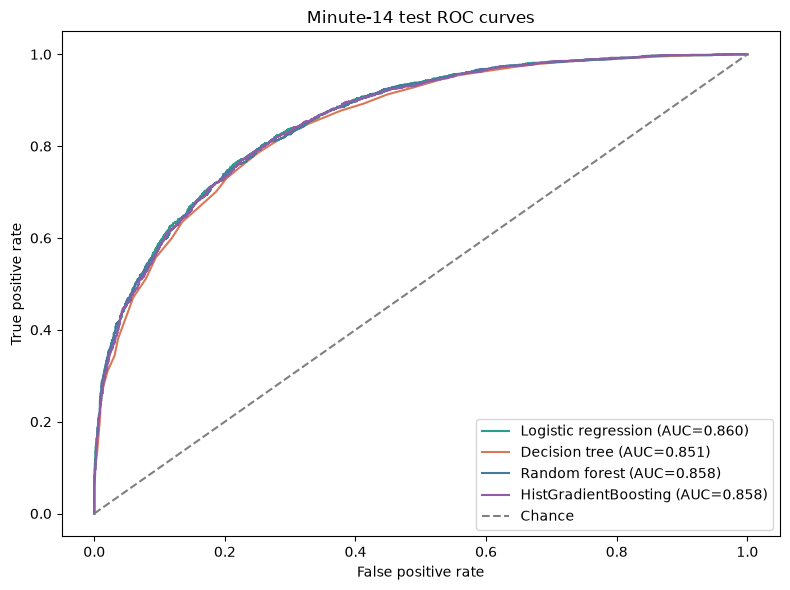

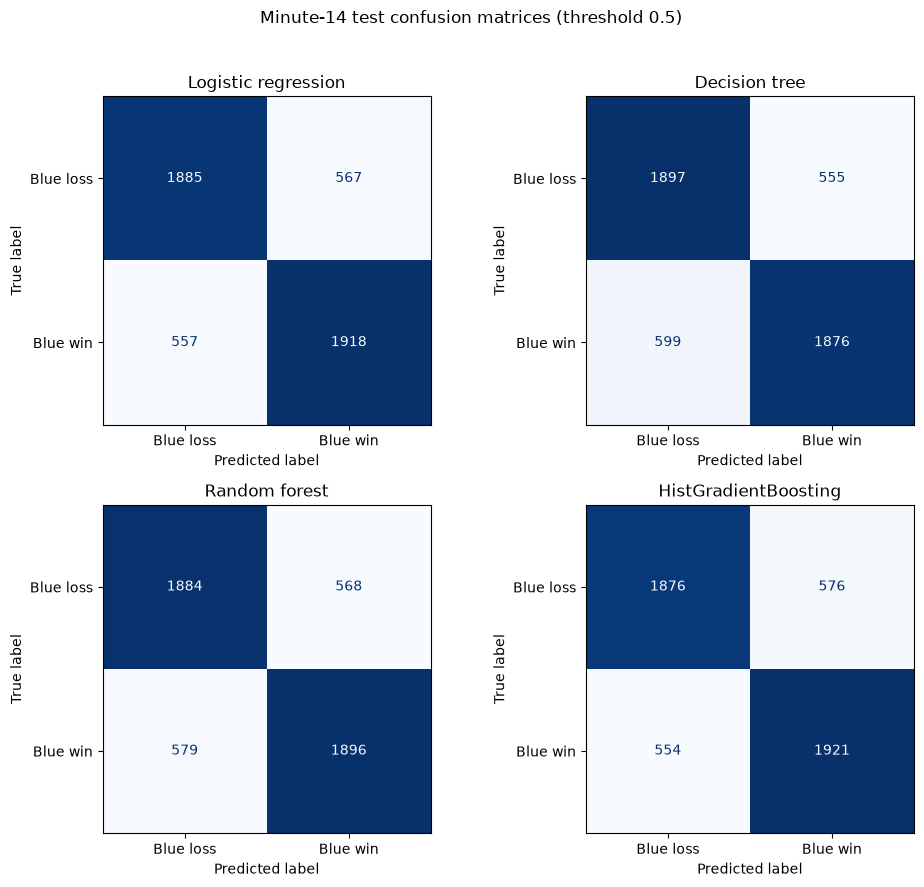

In [6]:
primary_predictions = predictions.loc[predictions["minute"].eq(PRIMARY_MINUTE)].copy()
fig, ax = plt.subplots(figsize=(8, 6))
roc_rows = []
for name in MODEL_ORDER:
    frame = primary_predictions.loc[primary_predictions["model"].eq(name)]
    fpr, tpr, thresholds = roc_curve(frame["y_true"], frame["p_blue_win"])
    auc = roc_auc_score(frame["y_true"], frame["p_blue_win"])
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", color=MODEL_COLORS[name])
    roc_rows.extend({"minute": PRIMARY_MINUTE, "model": name, "fpr": float(f),
                     "tpr": float(t), "threshold": float(c)} for f, t, c in zip(fpr, tpr, thresholds))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Minute-14 test ROC curves")
ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "final_test_roc_minute14.png", dpi=180, bbox_inches="tight")
save_csv(pd.DataFrame(roc_rows), report_dir / "final_test_roc_points.csv")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
confusion_rows = []
for ax, name in zip(axes.flat, MODEL_ORDER):
    frame = primary_predictions.loc[primary_predictions["model"].eq(name)]
    matrix = confusion_matrix(frame["y_true"], frame["y_pred"], labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Blue loss", "Blue win"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(name)
    tn, fp, fn, tp = matrix.ravel()
    confusion_rows.append({"model": name, "minute": PRIMARY_MINUTE,
                           "true_negative": int(tn), "false_positive": int(fp),
                           "false_negative": int(fn), "true_positive": int(tp)})
fig.suptitle("Minute-14 test confusion matrices (threshold 0.5)")
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(figure_dir / "final_test_confusion_minute14.png", dpi=180, bbox_inches="tight")
save_csv(pd.DataFrame(confusion_rows), report_dir / "final_test_confusion_counts.csv")
plt.show()

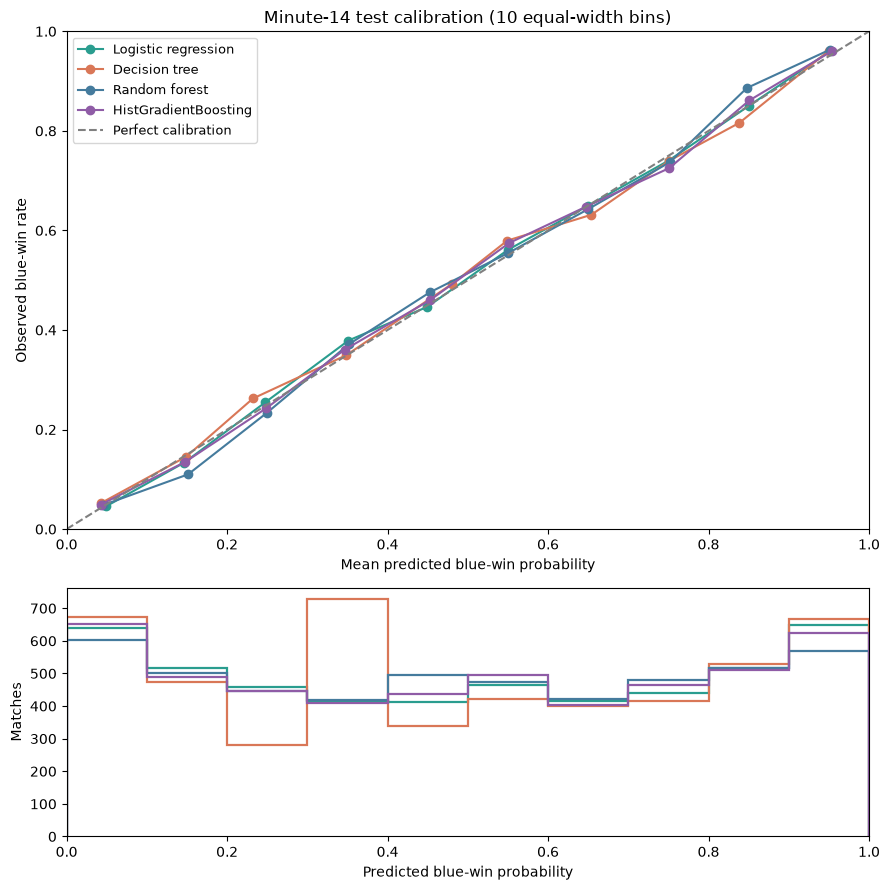

In [7]:
calibration_frames = []
for (minute, name), frame in predictions.groupby(["minute", "model"]):
    frame = frame.copy()
    frame["probability_bin"] = pd.cut(frame["p_blue_win"], np.linspace(0, 1, 11), include_lowest=True)
    bins = (frame.groupby("probability_bin", observed=True)
            .agg(matches=("y_true", "size"), mean_probability=("p_blue_win", "mean"),
                 observed_win_rate=("y_true", "mean")).reset_index())
    bins["probability_bin"] = bins["probability_bin"].astype(str)
    bins["minute"], bins["model"] = minute, name
    calibration_frames.append(bins)
calibration_bins = pd.concat(calibration_frames, ignore_index=True)
save_csv(calibration_bins, report_dir / "final_test_calibration_bins.csv")

fig, (ax, histogram_ax) = plt.subplots(2, 1, figsize=(9, 9), gridspec_kw={"height_ratios": [2, 1]})
for name in MODEL_ORDER:
    bins = calibration_bins.loc[calibration_bins["minute"].eq(PRIMARY_MINUTE)
                                & calibration_bins["model"].eq(name)]
    ax.plot(bins["mean_probability"], bins["observed_win_rate"], marker="o",
            color=MODEL_COLORS[name], label=name)
    probabilities = primary_predictions.loc[primary_predictions["model"].eq(name), "p_blue_win"]
    histogram_ax.hist(probabilities, bins=np.linspace(0, 1, 11), histtype="step",
                      linewidth=1.6, color=MODEL_COLORS[name], label=name)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted blue-win probability",
       ylabel="Observed blue-win rate", title="Minute-14 test calibration (10 equal-width bins)")
ax.legend(fontsize=9)
histogram_ax.set(xlabel="Predicted blue-win probability", ylabel="Matches", xlim=(0, 1))
fig.tight_layout()
fig.savefig(figure_dir / "final_test_calibration_minute14.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Prediction time and the changing cohort

The normal comparison includes all eligible test matches at each minute. A second table restricts every minute to the same matches that have predictions at all four times. This common cohort is conditional on surviving to the latest prediction time; it is not representative of all minute-10 matches.

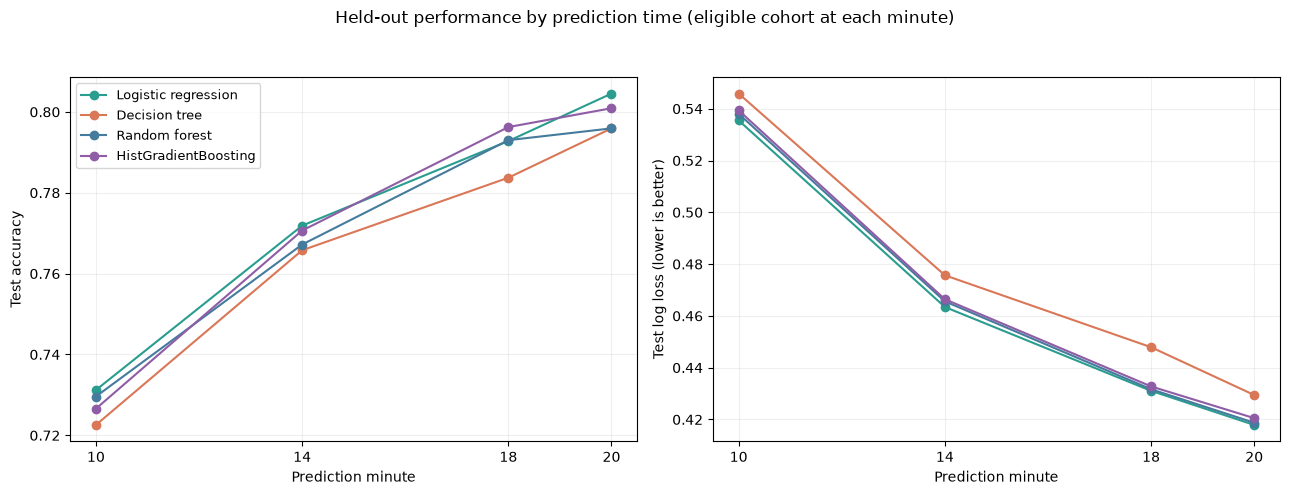

,minute,n_train,n_test
0,10,19912,4978
4,14,19723,4927
8,18,18565,4633
12,20,17738,4415


Common surviving cohort: 4,415 matches at every minute.


,minute,model,n_test,accuracy,roc_auc,log_loss,brier
0,10,Decision tree,4415,0.6895,0.7544,0.5935,0.2022
1,10,HistGradientBoosting,4415,0.6938,0.7605,0.5866,0.1996
2,10,Logistic regression,4415,0.6988,0.7631,0.5825,0.1984
3,10,Random forest,4415,0.6965,0.7607,0.5851,0.1994
4,14,Decision tree,4415,0.7386,0.8171,0.5237,0.1746
5,14,HistGradientBoosting,4415,0.7441,0.8244,0.5141,0.1711
6,14,Logistic regression,4415,0.7454,0.8268,0.5107,0.1699
7,14,Random forest,4415,0.7402,0.8254,0.5122,0.1706
8,18,Decision tree,4415,0.7730,0.8609,0.4687,0.1517
9,18,HistGradientBoosting,4415,0.7862,0.8678,0.4528,0.1480


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in MODEL_ORDER:
    frame = final_metrics.loc[final_metrics["model"].eq(name)].sort_values("minute")
    for ax, metric in zip(axes, ("accuracy", "log_loss")):
        ax.plot(frame["minute"], frame[metric], marker="o", color=MODEL_COLORS[name], label=name)
for ax, ylabel in zip(axes, ("Test accuracy", "Test log loss (lower is better)")):
    ax.set(xlabel="Prediction minute", ylabel=ylabel)
    ax.set_xticks(MINUTES)
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=9)
fig.suptitle("Held-out performance by prediction time (eligible cohort at each minute)")
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(figure_dir / "final_test_by_minute.png", dpi=180, bbox_inches="tight")
plt.show()

cohort_table = final_metrics[["minute", "n_train", "n_test"]].drop_duplicates().sort_values("minute")
display(cohort_table)
common_ids = set.intersection(*[
    set(predictions.loc[predictions["minute"].eq(minute), "gameId"]) for minute in MINUTES
])
common_rows = []
for (minute, name), frame in predictions.loc[predictions["gameId"].isin(common_ids)].groupby(["minute", "model"]):
    common_rows.append({"minute": int(minute), "model": name, **score_predictions(frame)})
common_cohort_metrics = pd.DataFrame(common_rows)
save_csv(common_cohort_metrics, report_dir / "final_test_common_cohort.csv")
print(f"Common surviving cohort: {len(common_ids):,} matches at every minute.")
display(common_cohort_metrics.round(4))

## 8. Confident errors and large-lead reversals

Confidence is `max(p_blue_win, 1 - p_blue_win)`. A confident error is a wrong prediction with confidence at least 0.90. The descriptive large-lead threshold is 3,000 gold. These thresholds define summaries only and do not alter model predictions.

Case tables use features available at the prediction minute. They can suggest observed patterns, but the dataset does not establish the unrecorded gameplay cause of a reversal. Minute-10 trajectory fields remain missing in descriptive tables because no earlier history is available.

In [9]:
state_columns = ["goldDiff", "expDiff", "champLevelDiff", "dragonDiff", "killShare",
                 "killDeathDiff", "outerTurretDiff", "totalTurretDiff",
                 "goldChange4", "goldSlope", "goldVolatility", "leadChanges"]
states = []
for minute, table in feature_tables.items():
    available = [column for column in state_columns if column in table]
    state = table.loc[table["gameId"].isin(test_ids), ["gameId"] + available].copy()
    state["minute"] = minute
    states.append(state)
test_states = pd.concat(states, ignore_index=True)
analysis = predictions.merge(test_states, on=["gameId", "minute"], validate="many_to_one")
assert len(analysis) == len(predictions)
analysis["wrong"] = analysis["y_pred"].ne(analysis["y_true"])
analysis["confidence"] = np.maximum(analysis["p_blue_win"], 1 - analysis["p_blue_win"])
analysis["confident_wrong"] = analysis["wrong"] & analysis["confidence"].ge(CONFIDENCE_CUTOFF)
analysis["error_type"] = np.select(
    [analysis["wrong"] & analysis["y_pred"].eq(1), analysis["wrong"] & analysis["y_pred"].eq(0)],
    ["False positive (predicted win)", "False negative (predicted loss)"], default="Correct")
confident_errors = analysis.loc[analysis["confident_wrong"]].sort_values("confidence", ascending=False)
save_csv(confident_errors, report_dir / "confident_errors.csv")

error_summary = (analysis.groupby(["minute", "model"])
                 .agg(matches=("wrong", "size"), errors=("wrong", "sum"), error_rate=("wrong", "mean"),
                      confident_errors=("confident_wrong", "sum"), mean_confidence=("confidence", "mean"))
                 .reset_index())
save_csv(error_summary, report_dir / "final_error_summary.csv")
display(error_summary.round(4))

case_columns = ["gameId", "y_true", "y_pred", "p_blue_win", "confidence", "wrong", "error_type"] + state_columns
primary_cases = analysis.loc[analysis["minute"].eq(PRIMARY_MINUTE) & analysis["model"].eq(PRIMARY_MODEL)]
primary_wrong = primary_cases.loc[primary_cases["wrong"]].sort_values("confidence", ascending=False)
print(f"Most confident minute-14 errors for the CV-preferred model ({PRIMARY_MODEL}):")
display(primary_wrong[case_columns].head(10).round(4))

large_lead_losses = primary_cases.loc[
    primary_cases["goldDiff"].ge(LARGE_GOLD_LEAD) & primary_cases["y_true"].eq(0)
].sort_values("goldDiff", ascending=False)
large_deficit_wins = primary_cases.loc[
    primary_cases["goldDiff"].le(-LARGE_GOLD_LEAD) & primary_cases["y_true"].eq(1)
].sort_values("goldDiff")
save_csv(large_lead_losses, report_dir / "minute14_large_lead_losses.csv")
save_csv(large_deficit_wins, report_dir / "minute14_large_deficit_wins.csv")
print(f"Blue led by at least {LARGE_GOLD_LEAD:,} gold at minute 14 but lost: {len(large_lead_losses):,} matches.")
display(large_lead_losses[case_columns].head(10).round(4))
print(f"Blue trailed by at least {LARGE_GOLD_LEAD:,} gold at minute 14 but won: {len(large_deficit_wins):,} matches.")
display(large_deficit_wins[case_columns].head(10).round(4))

for label, mask in [("Large lead", primary_cases["goldDiff"].ge(LARGE_GOLD_LEAD)),
                    ("Large deficit", primary_cases["goldDiff"].le(-LARGE_GOLD_LEAD))]:
    subset = primary_cases.loc[mask]
    reversals = len(large_lead_losses) if label == "Large lead" else len(large_deficit_wins)
    rate = reversals / len(subset) if len(subset) else np.nan
    print(f"{label}: {reversals:,} reversals / {len(subset):,} matches ({rate:.1%}).")

,minute,model,matches,errors,error_rate,confident_errors,mean_confidence
0,10,Decision tree,4978,1381,0.2774,74,0.7247
1,10,HistGradientBoosting,4978,1361,0.2734,45,0.7257
2,10,Logistic regression,4978,1338,0.2688,35,0.7273
3,10,Random forest,4978,1346,0.2704,37,0.7242
4,14,Decision tree,4927,1154,0.2342,61,0.7705
5,14,HistGradientBoosting,4927,1130,0.2293,57,0.7697
6,14,Logistic regression,4927,1124,0.2281,55,0.7715
7,14,Random forest,4927,1147,0.2328,50,0.7621
8,18,Decision tree,4633,1002,0.2163,59,0.7954
9,18,HistGradientBoosting,4633,944,0.2038,76,0.7975


Most confident minute-14 errors for the CV-preferred model (Logistic regression):


,gameId,y_true,y_pred,p_blue_win,confidence,wrong,error_type,goldDiff,expDiff,champLevelDiff,dragonDiff,killShare,killDeathDiff,outerTurretDiff,totalTurretDiff,goldChange4,goldSlope,goldVolatility,leadChanges
22551,4542619089,1,0,0.0147,0.9853,True,False negative (predicted loss),-8376,-6493,-1.2,-2,0.1818,-14,-1,-1,-4295.0,-1073.75,932.6738,0.0
23516,4521071452,1,0,0.0198,0.9802,True,False negative (predicted loss),-7109,-8187,-1.6,-1,0.2500,-12,0,0,-4599.0,-1149.75,1127.8353,0.0
24208,4401337188,1,0,0.0212,0.9788,True,False negative (predicted loss),-7277,-7647,-1.4,-1,0.2593,-13,0,0,-2749.0,-687.25,297.6920,0.0
23130,4529020760,1,0,0.0213,0.9787,True,False negative (predicted loss),-7848,-5286,-1.0,-2,0.1765,-11,-1,-1,-4556.0,-1139.00,292.7422,0.0
24113,4543688797,1,0,0.0224,0.9776,True,False negative (predicted loss),-9995,-5239,-0.8,0,0.3125,-6,-1,-3,-3712.0,-928.00,1622.1030,0.0
21689,4519650812,0,1,0.9692,0.9692,True,False positive (predicted win),9645,4989,1.0,-1,0.7619,11,2,2,4446.0,1111.50,524.6732,0.0
23876,4534629528,1,0,0.0317,0.9683,True,False negative (predicted loss),-6368,-5571,-1.2,-2,0.3077,-10,0,0,-5215.0,-1303.75,553.6646,0.0
23374,4462636555,0,1,0.9634,0.9634,True,False positive (predicted win),6663,4277,1.0,2,0.6842,14,1,1,4397.0,1099.25,1823.6284,0.0
21054,4545087272,0,1,0.9592,0.9592,True,False positive (predicted win),7264,4461,1.0,1,0.6111,4,3,3,5990.0,1497.50,1067.7312,0.0
22950,4426978948,1,0,0.0437,0.9563,True,False negative (predicted loss),-5850,-4620,-1.0,-2,0.3182,-8,-1,-1,-1516.0,-379.00,1043.6896,0.0


Blue led by at least 3,000 gold at minute 14 but lost: 106 matches.


,gameId,y_true,y_pred,p_blue_win,confidence,wrong,error_type,goldDiff,expDiff,champLevelDiff,dragonDiff,killShare,killDeathDiff,outerTurretDiff,totalTurretDiff,goldChange4,goldSlope,goldVolatility,leadChanges
21689,4519650812,0,1,0.9692,0.9692,True,False positive (predicted win),9645,4989,1.0,-1,0.7619,11,2,2,4446.0,1111.50,524.6732,0.0
21054,4545087272,0,1,0.9592,0.9592,True,False positive (predicted win),7264,4461,1.0,1,0.6111,4,3,3,5990.0,1497.50,1067.7312,0.0
22205,4546195429,0,1,0.9505,0.9505,True,False positive (predicted win),6822,3837,1.0,1,0.6774,11,1,1,3480.0,870.00,3102.7846,0.0
23827,4545763602,0,1,0.9317,0.9317,True,False positive (predicted win),6787,3332,1.0,0,0.7368,9,3,3,1723.0,430.75,591.8484,0.0
23374,4462636555,0,1,0.9634,0.9634,True,False positive (predicted win),6663,4277,1.0,2,0.6842,14,1,1,4397.0,1099.25,1823.6284,0.0
21269,4406066773,0,1,0.9460,0.9460,True,False positive (predicted win),6472,4013,0.4,1,0.6190,10,1,1,3711.0,927.75,490.0250,0.0
24603,4448468440,0,1,0.9456,0.9456,True,False positive (predicted win),6365,2479,1.0,2,0.7222,8,0,0,6162.0,1540.50,1347.7455,0.0
22842,4400704645,0,1,0.9561,0.9561,True,False positive (predicted win),6320,3872,0.6,2,0.6522,7,2,2,3157.0,789.25,712.0565,0.0
20678,4533468782,0,1,0.9468,0.9468,True,False positive (predicted win),6185,3153,0.8,2,0.6111,4,1,2,2851.0,712.75,1785.4446,0.0
23163,4395522621,0,1,0.9210,0.9210,True,False positive (predicted win),6102,5018,1.2,-1,0.6579,12,2,3,764.0,191.00,14.1421,0.0


Blue trailed by at least 3,000 gold at minute 14 but won: 97 matches.


,gameId,y_true,y_pred,p_blue_win,confidence,wrong,error_type,goldDiff,expDiff,champLevelDiff,dragonDiff,killShare,killDeathDiff,outerTurretDiff,totalTurretDiff,goldChange4,goldSlope,goldVolatility,leadChanges
24113,4543688797,1,0,0.0224,0.9776,True,False negative (predicted loss),-9995,-5239,-0.8,0,0.3125,-6,-1,-3,-3712.0,-928.00,1622.1030,0.0
22551,4542619089,1,0,0.0147,0.9853,True,False negative (predicted loss),-8376,-6493,-1.2,-2,0.1818,-14,-1,-1,-4295.0,-1073.75,932.6738,0.0
23130,4529020760,1,0,0.0213,0.9787,True,False negative (predicted loss),-7848,-5286,-1.0,-2,0.1765,-11,-1,-1,-4556.0,-1139.00,292.7422,0.0
24529,4383231600,1,0,0.0628,0.9372,True,False negative (predicted loss),-7830,-5449,-0.8,2,0.3333,-9,-2,-2,-6336.0,-1584.00,2868.0251,0.0
22538,4527970110,1,0,0.0503,0.9497,True,False negative (predicted loss),-7763,-5199,-1.2,1,0.2667,-7,-1,-2,-2557.0,-639.25,942.5733,0.0
24027,4413299216,1,0,0.0592,0.9408,True,False negative (predicted loss),-7309,-3240,-1.0,0,0.1429,-15,-1,-1,-4848.0,-1212.00,156.9777,0.0
24208,4401337188,1,0,0.0212,0.9788,True,False negative (predicted loss),-7277,-7647,-1.4,-1,0.2593,-13,0,0,-2749.0,-687.25,297.6920,0.0
23516,4521071452,1,0,0.0198,0.9802,True,False negative (predicted loss),-7109,-8187,-1.6,-1,0.2500,-12,0,0,-4599.0,-1149.75,1127.8353,0.0
22583,4546700612,1,0,0.0595,0.9405,True,False negative (predicted loss),-6904,-4251,-0.8,0,0.3158,-7,-2,-2,-3296.0,-824.00,247.4874,0.0
23882,4469472842,1,0,0.1252,0.8748,True,False negative (predicted loss),-6649,-3178,-0.4,2,0.3235,-12,-1,-1,-2048.0,-512.00,748.1190,0.0


Large lead: 106 reversals / 1,137 matches (9.3%).
Large deficit: 97 reversals / 1,108 matches (8.8%).


## 9. Conditions associated with prediction errors

Report sample counts alongside error rates. Gold bins use absolute differences: below 1,000; 1,000 to below 3,000; and at least 3,000. Other slices describe whether blue is ahead or behind in gold, dragons, and outer turrets. These are descriptive held-out comparisons, not new feature-selection experiments.

Minute-14 slices for the CV-preferred model:


,minute,model,slice,matches,errors,error_rate,confident_errors,mean_confidence,dimension
18,14,Logistic regression,"<1,000",999,401,0.4014,0,0.5982,absolute_gold_bin
19,14,Logistic regression,"1,000–<3,000",1683,520,0.3090,1,0.7033,absolute_gold_bin
20,14,Logistic regression,"≥3,000",2245,203,0.0904,54,0.8998,absolute_gold_bin
60,14,Logistic regression,Blue ahead,2504,565,0.2256,26,0.7674,gold_position
61,14,Logistic regression,Blue behind,2423,559,0.2307,29,0.7758,gold_position
98,14,Logistic regression,Blue ahead,1859,413,0.2222,25,0.7867,dragon_position
99,14,Logistic regression,Blue behind,2040,455,0.2230,24,0.7777,dragon_position
100,14,Logistic regression,Tied,1028,256,0.2490,6,0.7317,dragon_position
146,14,Logistic regression,Blue ahead,1357,267,0.1968,22,0.8101,outer_turret_position
147,14,Logistic regression,Blue behind,1207,216,0.1790,18,0.8168,outer_turret_position


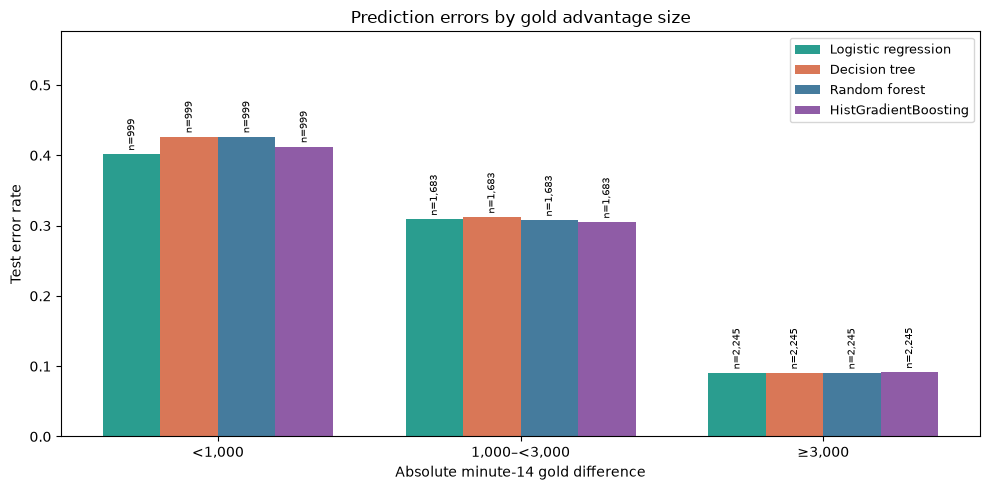

,minute,model_a,model_b,matches,both_wrong,either_wrong,error_overlap_jaccard
0,14,Logistic regression,Decision tree,4927,1019,1259,0.8094
1,14,Logistic regression,Random forest,4927,1060,1211,0.8753
2,14,Logistic regression,HistGradientBoosting,4927,1035,1219,0.8491
3,14,Decision tree,Random forest,4927,1035,1266,0.8175
4,14,Decision tree,HistGradientBoosting,4927,1008,1276,0.7900
5,14,Random forest,HistGradientBoosting,4927,1038,1239,0.8378


In [10]:
analysis["absolute_gold_bin"] = pd.cut(analysis["goldDiff"].abs(), [0, 1000, 3000, np.inf],
                                       labels=["<1,000", "1,000–<3,000", "≥3,000"], right=False)
def advantage_label(values):
    return np.select([values.gt(0), values.lt(0)], ["Blue ahead", "Blue behind"], default="Tied")
analysis["gold_position"] = advantage_label(analysis["goldDiff"])
analysis["dragon_position"] = advantage_label(analysis["dragonDiff"])
analysis["outer_turret_position"] = advantage_label(analysis["outerTurretDiff"])

slice_frames = []
for dimension in ("absolute_gold_bin", "gold_position", "dragon_position", "outer_turret_position"):
    table = (analysis.groupby(["minute", "model", dimension], observed=True)
             .agg(matches=("wrong", "size"), errors=("wrong", "sum"), error_rate=("wrong", "mean"),
                  confident_errors=("confident_wrong", "sum"), mean_confidence=("confidence", "mean"))
             .reset_index().rename(columns={dimension: "slice"}))
    table["slice"] = table["slice"].astype(str)
    table["dimension"] = dimension
    slice_frames.append(table)
error_slices = pd.concat(slice_frames, ignore_index=True)
save_csv(error_slices, report_dir / "error_slices.csv")
print("Minute-14 slices for the CV-preferred model:")
display(error_slices.loc[error_slices["minute"].eq(PRIMARY_MINUTE)
                         & error_slices["model"].eq(PRIMARY_MODEL)].round(4))

gold_slice = error_slices.loc[error_slices["minute"].eq(PRIMARY_MINUTE)
                             & error_slices["dimension"].eq("absolute_gold_bin")]
gold_labels = ["<1,000", "1,000–<3,000", "≥3,000"]
fig, ax = plt.subplots(figsize=(10, 5))
width = 0.19
for j, name in enumerate(MODEL_ORDER):
    frame = gold_slice.loc[gold_slice["model"].eq(name)].set_index("slice").reindex(gold_labels)
    positions = np.arange(len(gold_labels)) + (j - 1.5) * width
    ax.bar(positions, frame["error_rate"], width, color=MODEL_COLORS[name], label=name)
    for x, (_, row) in zip(positions, frame.iterrows()):
        if pd.notna(row["matches"]):
            ax.text(x, row["error_rate"] + 0.005, f"n={int(row['matches']):,}",
                    ha="center", va="bottom", rotation=90, fontsize=7)
ax.set_xticks(np.arange(len(gold_labels)), gold_labels)
ax.set(xlabel="Absolute minute-14 gold difference", ylabel="Test error rate",
       title="Prediction errors by gold advantage size")
highest = gold_slice["error_rate"].max()
ax.set_ylim(0, min(1.15, max(0.2, highest + 0.15)))
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(figure_dir / "final_error_by_gold.png", dpi=180, bbox_inches="tight")
plt.show()

wrong_matrix = analysis.loc[analysis["minute"].eq(PRIMARY_MINUTE)].pivot(
    index="gameId", columns="model", values="wrong").reindex(columns=MODEL_ORDER)
agreement_rows = []
for i, first in enumerate(MODEL_ORDER):
    for second in MODEL_ORDER[i + 1:]:
        both = int((wrong_matrix[first] & wrong_matrix[second]).sum())
        either = int((wrong_matrix[first] | wrong_matrix[second]).sum())
        agreement_rows.append({"minute": PRIMARY_MINUTE, "model_a": first, "model_b": second,
                                "matches": len(wrong_matrix), "both_wrong": both,
                                "either_wrong": either, "error_overlap_jaccard": both / either if either else np.nan})
error_overlap = pd.DataFrame(agreement_rows)
save_csv(error_overlap, report_dir / "final_error_overlap.csv")
display(error_overlap.round(4))

## 10. Findings and submission handoff

The following summary is generated from this locked evaluation. It records the preferred model chosen from CV, its observed test performance, and descriptive error patterns. Add a short discussion of representative match IDs using the case tables above, without changing model choices after observing the test set.

In [11]:
preferred_test = primary_metrics.loc[primary_metrics["model"].eq(PRIMARY_MODEL)].iloc[0]
preferred_slices = error_slices.loc[error_slices["minute"].eq(PRIMARY_MINUTE)
                                   & error_slices["model"].eq(PRIMARY_MODEL)
                                   & error_slices["dimension"].eq("absolute_gold_bin")]
slice_notes = []
for row in preferred_slices.itertuples():
    slice_notes.append(f"- Absolute gold difference {row.slice}: {row.errors:,} errors / {row.matches:,} matches "
                       f"({row.error_rate:.1%} error rate).")
confident_primary = primary_cases.loc[primary_cases["confident_wrong"]]
examples = []
for row in primary_wrong.head(3).itertuples():
    examples.append(f"- Match {row.gameId}: predicted blue-win probability {row.p_blue_win:.3f}, "
                    f"actual outcome {'blue win' if row.y_true else 'blue loss'}, "
                    f"gold difference {row.goldDiff:,.0f}, experience difference {row.expDiff:,.0f}, "
                    f"dragon difference {row.dragonDiff:,.0f}.")

findings = f"""# Final evaluation findings

The preferred minute-14 model selected before test inspection was **{PRIMARY_MODEL}**. After refitting on {int(preferred_test.n_train):,} training matches, it achieved **{preferred_test.accuracy:.2%} accuracy**, **{preferred_test.roc_auc:.4f} ROC AUC**, **{preferred_test.log_loss:.4f} log loss**, and **{preferred_test.brier:.4f} Brier score** on {int(preferred_test.n_test):,} reserved test matches. Its training-selection CV log loss was {preferred_test.cv_log_loss:.4f}.

The four-model comparison and probability diagnostics are in the tables and figures above. Calibration curves describe reliability; no calibrator was fitted on test data. Final configurations remain those frozen before evaluation.

## Error patterns for the CV-preferred model at minute 14

There were {len(primary_wrong):,} errors, including {len(confident_primary):,} wrong predictions with confidence at least {CONFIDENCE_CUTOFF:.0%}.

{chr(10).join(slice_notes)}

There were {len(large_lead_losses):,} matches where blue led by at least {LARGE_GOLD_LEAD:,} gold but lost, and {len(large_deficit_wins):,} where blue trailed by at least {LARGE_GOLD_LEAD:,} gold but won. These outcome reversals are distinct from model errors: some reversals may have been predicted correctly.

## Representative model errors

{chr(10).join(examples) if examples else 'The preferred model made no errors in this evaluation.'}

These recorded states support descriptive case analysis, not a causal explanation of unobserved gameplay events. Later-minute comparisons change the eligible cohort; the common-survivor table provides an additional conditional comparison.

## Submission handoff

Combine notebooks 01–05 into one submission organized as Introduction → Exploration & Preprocessing → Modeling → Results & Analysis. Include final model choices, the four-model test table, ROC/confusion/calibration plots, representative errors, and limitations. Ensure the final notebook regenerates required inputs from the raw CSV, then restart and Run All to verify reproducibility while preserving the frozen choices.
"""
findings_path = report_dir / "final_evaluation_findings.md"
findings_path.write_text(findings)
display(Markdown(findings))
print("Saved findings:", findings_path)
print("Frozen specifications:", manifest_path)
print("Final predictions:", report_dir / "final_test_predictions.csv")

# Final evaluation findings

The preferred minute-14 model selected before test inspection was **Logistic regression**. After refitting on 19,723 training matches, it achieved **77.19% accuracy**, **0.8596 ROC AUC**, **0.4634 log loss**, and **0.1529 Brier score** on 4,927 reserved test matches. Its training-selection CV log loss was 0.4705.

The four-model comparison and probability diagnostics are in the tables and figures above. Calibration curves describe reliability; no calibrator was fitted on test data. Final configurations remain those frozen before evaluation.

## Error patterns for the CV-preferred model at minute 14

There were 1,124 errors, including 55 wrong predictions with confidence at least 90%.

- Absolute gold difference <1,000: 401 errors / 999 matches (40.1% error rate).
- Absolute gold difference 1,000–<3,000: 520 errors / 1,683 matches (30.9% error rate).
- Absolute gold difference ≥3,000: 203 errors / 2,245 matches (9.0% error rate).

There were 106 matches where blue led by at least 3,000 gold but lost, and 97 where blue trailed by at least 3,000 gold but won. These outcome reversals are distinct from model errors: some reversals may have been predicted correctly.

## Representative model errors

- Match 4542619089: predicted blue-win probability 0.015, actual outcome blue win, gold difference -8,376, experience difference -6,493, dragon difference -2.
- Match 4521071452: predicted blue-win probability 0.020, actual outcome blue win, gold difference -7,109, experience difference -8,187, dragon difference -1.
- Match 4401337188: predicted blue-win probability 0.021, actual outcome blue win, gold difference -7,277, experience difference -7,647, dragon difference -1.

These recorded states support descriptive case analysis, not a causal explanation of unobserved gameplay events. Later-minute comparisons change the eligible cohort; the common-survivor table provides an additional conditional comparison.

## Submission handoff

Combine notebooks 01–05 into one submission organized as Introduction → Exploration & Preprocessing → Modeling → Results & Analysis. Include final model choices, the four-model test table, ROC/confusion/calibration plots, representative errors, and limitations. Ensure the final notebook regenerates required inputs from the raw CSV, then restart and Run All to verify reproducibility while preserving the frozen choices.


Saved findings: /Users/home/Desktop/UT/26 Fall/CS 363M/CS-363M-ML-Project/reports/final_evaluation_findings.md
Frozen specifications: /Users/home/Desktop/UT/26 Fall/CS 363M/CS-363M-ML-Project/reports/final_model_specs.json
Final predictions: /Users/home/Desktop/UT/26 Fall/CS 363M/CS-363M-ML-Project/reports/final_test_predictions.csv
